In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

Matplotlib is building the font cache; this may take a moment.


In [2]:
from pathlib import Path

file_path = Path("../Data/cleaned_loan_dataset.csv")

In [3]:
df = pd.read_csv(file_path)

print("Dataset loaded successfully!")

Dataset loaded successfully!


In [4]:
df.shape
df.head()

,Customer_ID,Gender,Married,Dependents,Education,Self_Employed,Applicant_Income,Coapplicant_Income,Loan_Amount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,569,Female,No,0,Graduate,No,2378,0.0,9,360,1,Urban,N
1,15,Male,Yes,2,Graduate,No,1299,1086.0,17,120,1,Urban,Y
2,95,Male,No,0,Not Graduate,No,3620,0.0,25,120,1,Semiurban,Y
3,134,Male,Yes,0,Graduate,Yes,3459,0.0,25,120,1,Semiurban,Y
4,556,Male,Yes,1,Graduate,No,5468,1032.0,26,360,1,Semiurban,Y


In [6]:
df["TotalIncome"] = (
    df["Applicant_Income"] + df["Coapplicant_Income"]
)

In [8]:
df[
    ["Applicant_Income", "Coapplicant_Income", "TotalIncome"]
].head(10)
df["TotalIncome"].describe()

,TotalIncome
count,614.000000
mean,7024.705081
std,6458.663872
min,1442.000000
25%,4166.000000
50%,5416.500000
75%,7521.750000
max,81000.000000


In [10]:
df.columns.tolist()
df.isnull().sum()

,0
Customer_ID,0
Gender,0
Married,0
Dependents,0
Education,0
Self_Employed,0
Applicant_Income,0
Coapplicant_Income,0
Loan_Amount,0
Loan_Amount_Term,0


In [11]:
df.dtypes


,0
Customer_ID,int64
Gender,object
Married,object
Dependents,int64
Education,object
Self_Employed,object
Applicant_Income,int64
Coapplicant_Income,float64
Loan_Amount,int64
Loan_Amount_Term,int64


In [12]:
df[
    [
        "Applicant_Income",
        "Coapplicant_Income",
        "TotalIncome",
        "Loan_Amount",
        "Loan_Amount_Term"
    ]
].describe()

,Applicant_Income,Coapplicant_Income,TotalIncome,Loan_Amount,Loan_Amount_Term
count,614.000000,614.000000,614.000000,614.000000,614.000000
mean,5403.459283,1621.245798,7024.705081,142.022801,338.892508
std,6109.041673,2926.248369,6458.663872,87.083089,69.716355
min,150.000000,0.000000,1442.000000,9.000000,12.000000
25%,2877.500000,0.000000,4166.000000,98.000000,360.000000
50%,3812.500000,1188.500000,5416.500000,125.000000,360.000000
75%,5795.000000,2297.250000,7521.750000,164.750000,360.000000
max,81000.000000,41667.000000,81000.000000,700.000000,480.000000


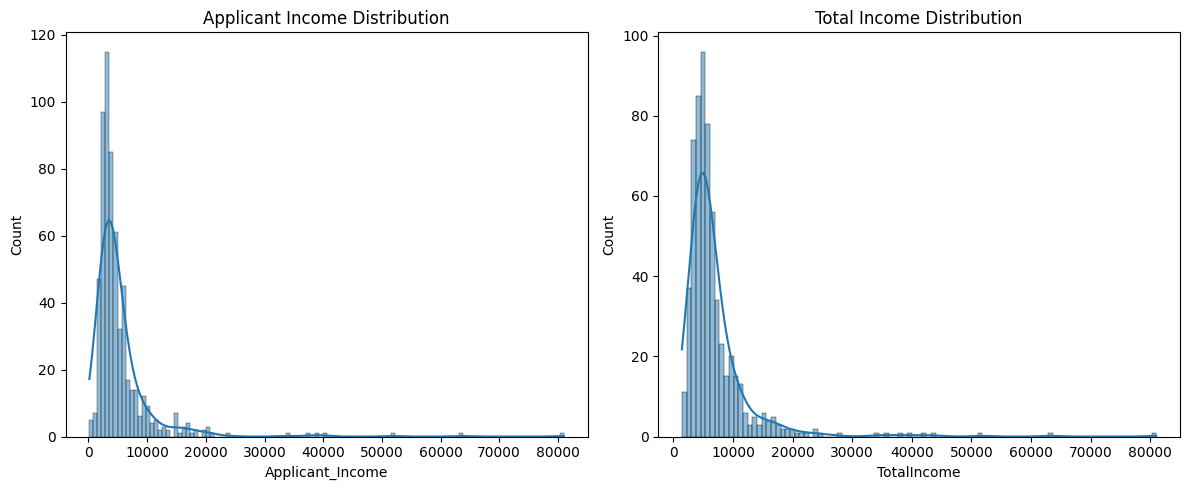

In [13]:
plt.figure(figsize=(12, 5))

plt.subplot(1, 2, 1)
sns.histplot(data=df, x="Applicant_Income", kde=True)
plt.title("Applicant Income Distribution")

plt.subplot(1, 2, 2)
sns.histplot(data=df, x="TotalIncome", kde=True)
plt.title("Total Income Distribution")

plt.tight_layout()
plt.show()

In [14]:
columns_to_check = [
    "Applicant_Income",
    "Coapplicant_Income",
    "TotalIncome",
    "Loan_Amount",
    "Loan_Amount_Term"
]

for col in columns_to_check:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)

    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    outliers = df[
        (df[col] < lower_bound) |
        (df[col] > upper_bound)
    ]

    print(f"\nColumn: {col}")
    print(f"Q1: {Q1:.2f}")
    print(f"Q3: {Q3:.2f}")
    print(f"IQR: {IQR:.2f}")
    print(f"Lower Bound: {lower_bound:.2f}")
    print(f"Upper Bound: {upper_bound:.2f}")
    print(f"Potential Outliers: {len(outliers)}")


Column: Applicant_Income
Q1: 2877.50
Q3: 5795.00
IQR: 2917.50
Lower Bound: -1498.75
Upper Bound: 10171.25
Potential Outliers: 50

Column: Coapplicant_Income
Q1: 0.00
Q3: 2297.25
IQR: 2297.25
Lower Bound: -3445.88
Upper Bound: 5743.12
Potential Outliers: 18

Column: TotalIncome
Q1: 4166.00
Q3: 7521.75
IQR: 3355.75
Lower Bound: -867.62
Upper Bound: 12555.38
Potential Outliers: 50

Column: Loan_Amount
Q1: 98.00
Q3: 164.75
IQR: 66.75
Lower Bound: -2.12
Upper Bound: 264.88
Potential Outliers: 41

Column: Loan_Amount_Term
Q1: 360.00
Q3: 360.00
IQR: 0.00
Lower Bound: 360.00
Upper Bound: 360.00
Potential Outliers: 97


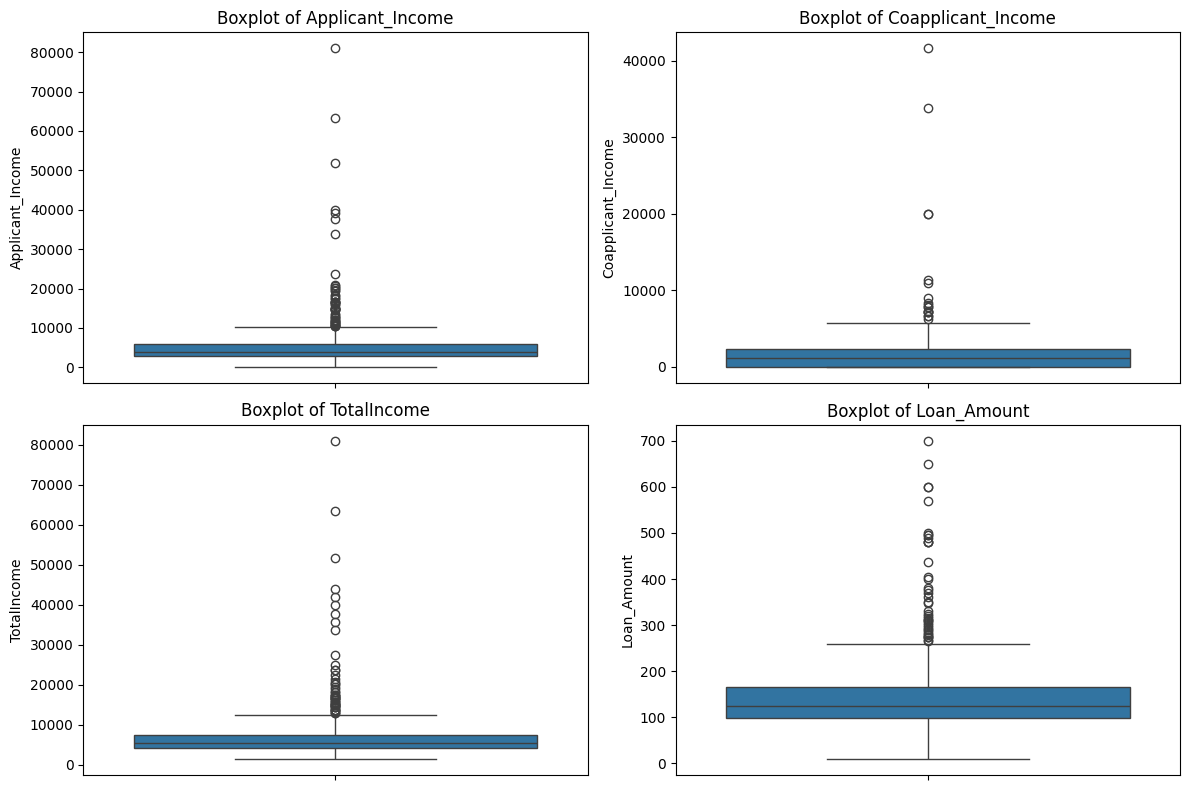

In [15]:
columns_to_plot = [
    "Applicant_Income",
    "Coapplicant_Income",
    "TotalIncome",
    "Loan_Amount"
]

plt.figure(figsize=(12, 8))

for i, col in enumerate(columns_to_plot, 1):
    plt.subplot(2, 2, i)
    sns.boxplot(y=df[col])
    plt.title(f"Boxplot of {col}")
    plt.ylabel(col)

plt.tight_layout()
plt.show()

In [16]:
df["Loan_Amount_Term"].value_counts().sort_index()

,count
Loan_Amount_Term,
12,1
36,2
60,2
84,4
120,12
180,44
240,4
300,13
360,517


In [18]:
df["Loan_Status"].value_counts()
df["Loan_Status"].value_counts(normalize=True) * 100

,proportion
Loan_Status,
Y,68.729642
N,31.270358


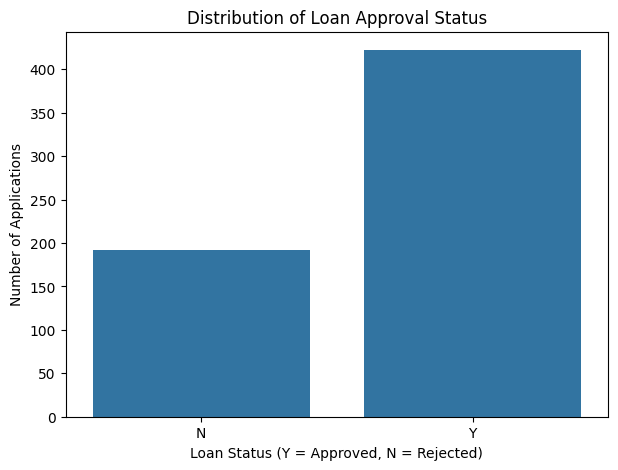

In [19]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Loan_Status")

plt.title("Distribution of Loan Approval Status")
plt.xlabel("Loan Status (Y = Approved, N = Rejected)")
plt.ylabel("Number of Applications")

plt.show()

In [20]:
pd.crosstab(df["Credit_History"], df["Loan_Status"])

Loan_Status,N,Y
Credit_History,,
0,82,10
1,110,412


In [21]:
pd.crosstab(
    df["Credit_History"],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status,N,Y
Credit_History,,
0,89.130435,10.869565
1,21.072797,78.927203


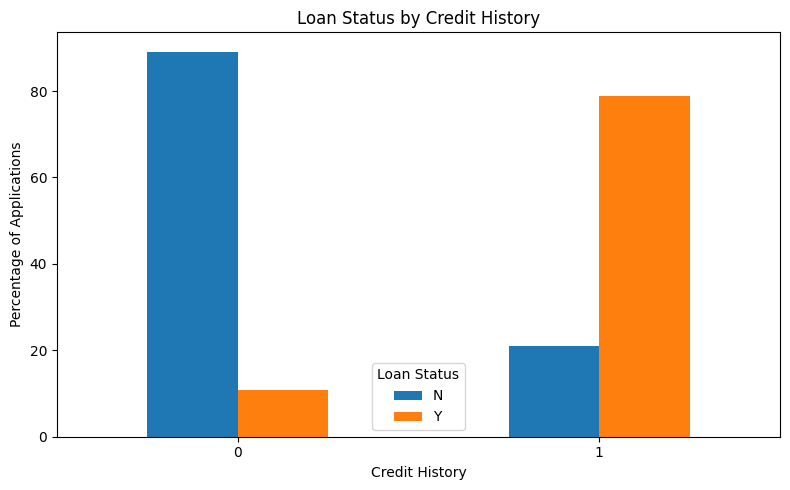

In [22]:
approval_rates = pd.crosstab(
    df["Credit_History"],
    df["Loan_Status"],
    normalize="index"
) * 100

approval_rates.plot(
    kind="bar",
    figsize=(8, 5)
)

plt.title("Loan Status by Credit History")
plt.xlabel("Credit History")
plt.ylabel("Percentage of Applications")
plt.xticks(rotation=0)
plt.legend(title="Loan Status")
plt.tight_layout()
plt.show()

In [23]:
df.groupby("Loan_Status")[
    [
        "Applicant_Income",
        "TotalIncome",
        "Loan_Amount"
    ]
].agg(["mean", "median"])

Applicant_Income          TotalIncome         Loan_Amount       
                        mean  median         mean  median        mean median
Loan_Status                                                                 
N                5446.078125  3833.5  7323.885417  5289.5  143.869792  126.5
Y                5384.068720  3812.5  6888.585118  5439.0  141.182464  125.0

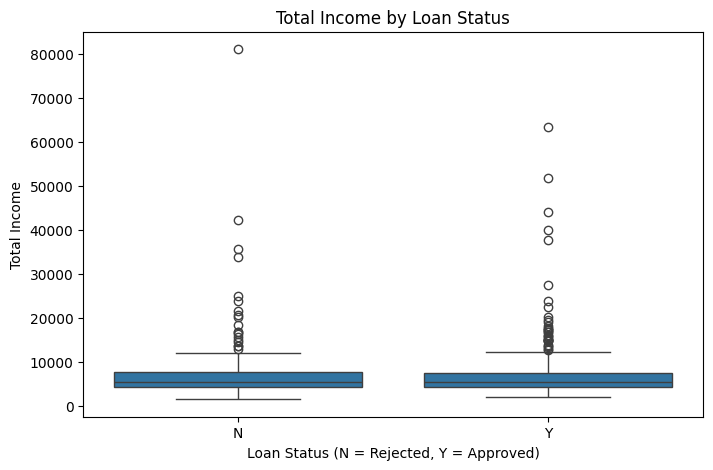

In [24]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Status",
    y="TotalIncome"
)

plt.title("Total Income by Loan Status")
plt.xlabel("Loan Status (N = Rejected, Y = Approved)")
plt.ylabel("Total Income")

plt.show()

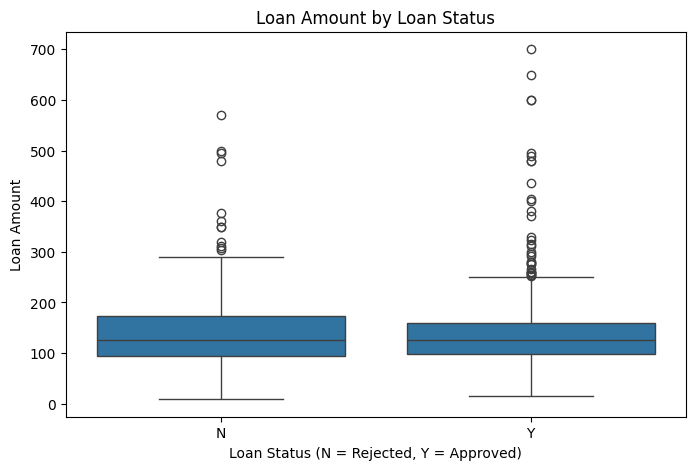

In [25]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Loan_Status",
    y="Loan_Amount"
)

plt.title("Loan Amount by Loan Status")
plt.xlabel("Loan Status (N = Rejected, Y = Approved)")
plt.ylabel("Loan Amount")

plt.show()

In [26]:
pd.crosstab(
    df["Education"],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status,N,Y
Education,,
Graduate,29.166667,70.833333
Not Graduate,38.805970,61.194030


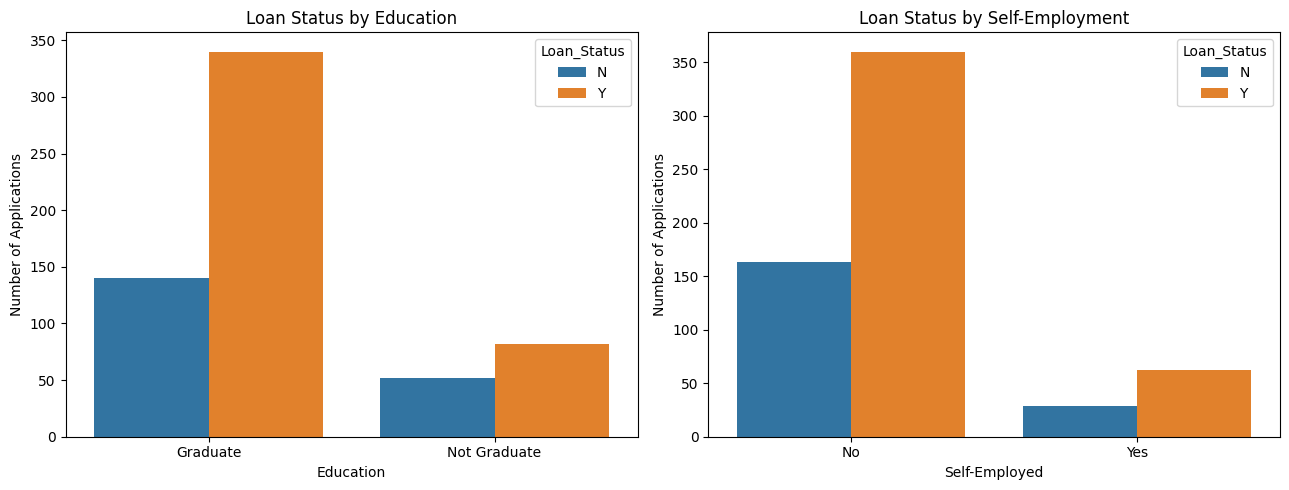

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

sns.countplot(
    data=df,
    x="Education",
    hue="Loan_Status",
    ax=axes[0]
)
axes[0].set_title("Loan Status by Education")
axes[0].set_xlabel("Education")
axes[0].set_ylabel("Number of Applications")

sns.countplot(
    data=df,
    x="Self_Employed",
    hue="Loan_Status",
    ax=axes[1]
)
axes[1].set_title("Loan Status by Self-Employment")
axes[1].set_xlabel("Self-Employed")
axes[1].set_ylabel("Number of Applications")

plt.tight_layout()
plt.show()

In [28]:
pd.crosstab(
    df["Self_Employed"],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status,N,Y
Self_Employed,,
No,31.166348,68.833652
Yes,31.868132,68.131868


In [29]:
pd.crosstab(
    df["Property_Area"],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status,N,Y
Property_Area,,
Rural,38.547486,61.452514
Semiurban,23.175966,76.824034
Urban,34.158416,65.841584


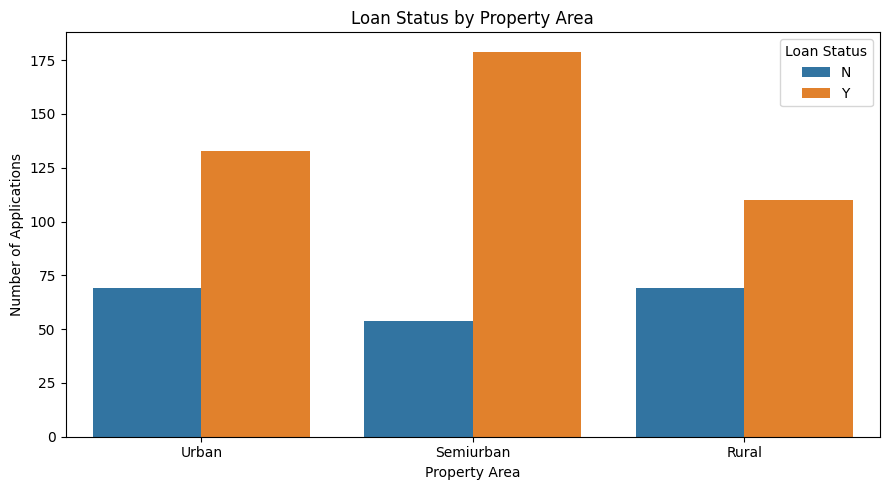

In [30]:
plt.figure(figsize=(9, 5))

sns.countplot(
    data=df,
    x="Property_Area",
    hue="Loan_Status"
)

plt.title("Loan Status by Property Area")
plt.xlabel("Property Area")
plt.ylabel("Number of Applications")
plt.legend(title="Loan Status")

plt.tight_layout()
plt.show()

In [31]:
property_approval = pd.crosstab(
    df["Property_Area"],
    df["Loan_Status"],
    normalize="index"
) * 100

property_approval["Approval_Rate"] = property_approval["Y"]

property_approval[["Approval_Rate"]].sort_values(
    by="Approval_Rate",
    ascending=False
)

Loan_Status,Approval_Rate
Property_Area,
Semiurban,76.824034
Urban,65.841584
Rural,61.452514


In [32]:
numeric_df = df.select_dtypes(include="number")

numeric_df.columns

Index(['Customer_ID', 'Dependents', 'Applicant_Income', 'Coapplicant_Income',
       'Loan_Amount', 'Loan_Amount_Term', 'Credit_History', 'TotalIncome'],
      dtype='object')

In [33]:
correlation_matrix = df[
    [
        "Applicant_Income",
        "Coapplicant_Income",
        "TotalIncome",
        "Loan_Amount",
        "Loan_Amount_Term",
        "Credit_History"
    ]
].corr()

correlation_matrix

,Applicant_Income,Coapplicant_Income,TotalIncome,Loan_Amount,Loan_Amount_Term,Credit_History
Applicant_Income,1.000000,-0.116605,0.893037,0.546275,-0.028039,-0.014902
Coapplicant_Income,-0.116605,1.000000,0.342781,0.191035,-0.048870,0.009719
TotalIncome,0.893037,0.342781,1.000000,0.603257,-0.048663,-0.009692
Loan_Amount,0.546275,0.191035,0.603257,1.000000,0.058471,0.007295
Loan_Amount_Term,-0.028039,-0.048870,-0.048663,0.058471,1.000000,0.056737
Credit_History,-0.014902,0.009719,-0.009692,0.007295,0.056737,1.000000


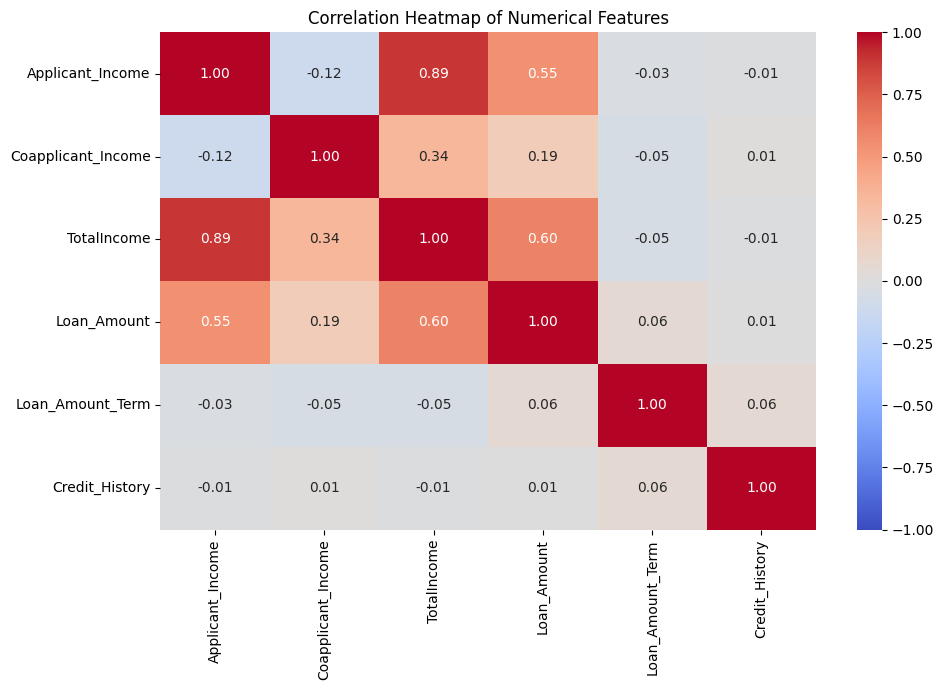

In [34]:
plt.figure(figsize=(10, 7))

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    vmin=-1,
    vmax=1
)

plt.title("Correlation Heatmap of Numerical Features")
plt.tight_layout()
plt.show()

In [35]:
pd.crosstab(
    [df["Education"], df["Credit_History"]],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status                          N          Y
Education    Credit_History                      
Graduate     0               86.363636  13.636364
             1               20.048309  79.951691
Not Graduate 0               96.153846   3.846154
             1               25.000000  75.000000

In [36]:
pd.crosstab(
    [df["Property_Area"], df["Credit_History"]],
    df["Loan_Status"],
    normalize="index"
) * 100

Loan_Status                           N          Y
Property_Area Credit_History                      
Rural         0               92.857143   7.142857
              1               28.476821  71.523179
Semiurban     0               81.250000  18.750000
              1               13.930348  86.069652
Urban         0               93.750000   6.250000
              1               22.941176  77.058824

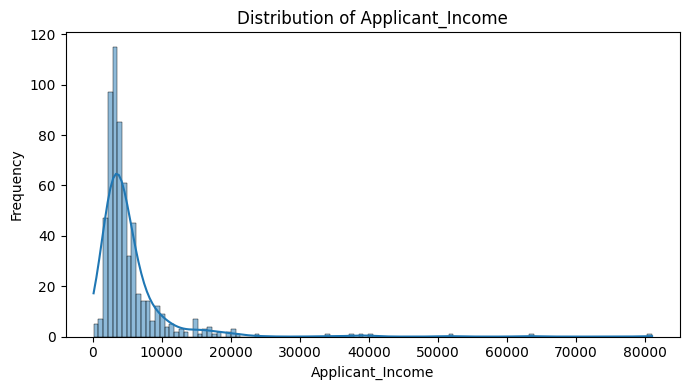

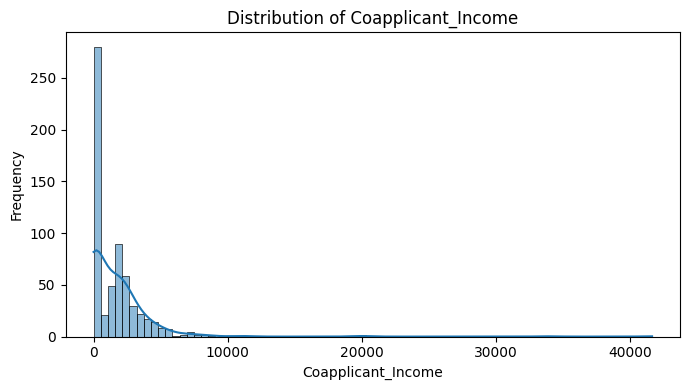

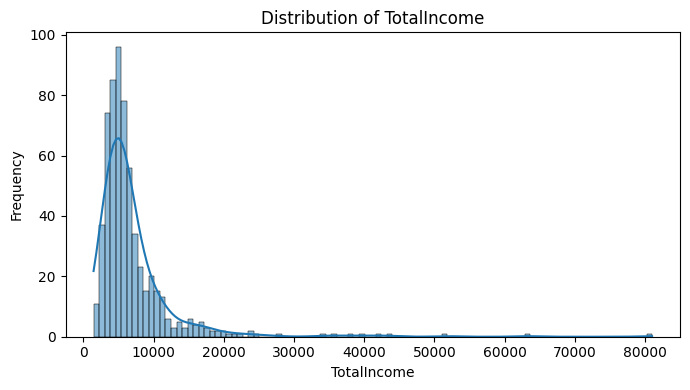

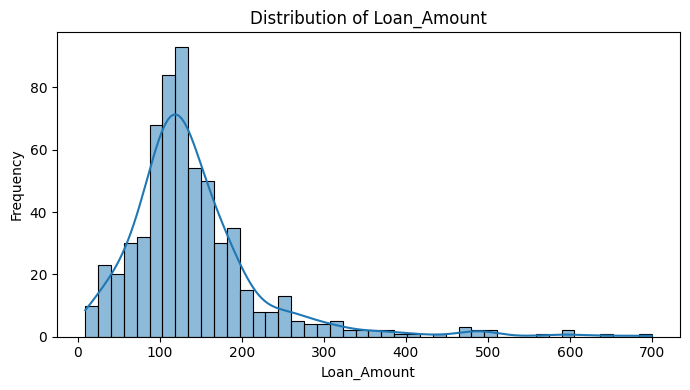

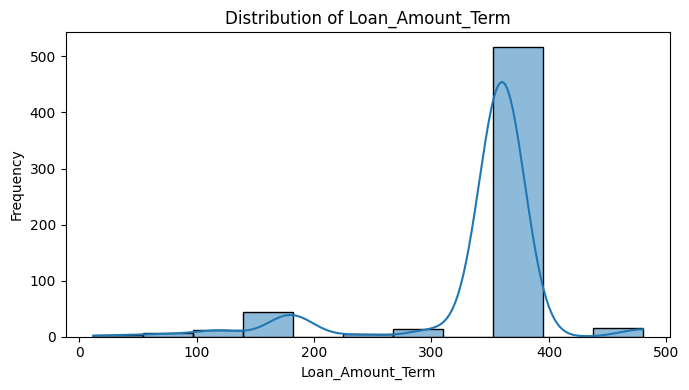

In [37]:
numerical_columns = [
    "Applicant_Income",
    "Coapplicant_Income",
    "TotalIncome",
    "Loan_Amount",
    "Loan_Amount_Term"
]

for col in numerical_columns:
    plt.figure(figsize=(7, 4))

    sns.histplot(data=df, x=col, kde=True)

    plt.title(f"Distribution of {col}")
    plt.xlabel(col)
    plt.ylabel("Frequency")

    plt.tight_layout()
    plt.show()

In [38]:
df.to_csv("loan_dataset_after_step_6.csv", index=False)

print("Dataset exported successfully!")

Dataset exported successfully!


In [39]:
from google.colab import files

files.download("loan_dataset_after_step_6.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>